# Notebook 03 — Regressão linear múltipla

Este notebook estima o modelo de regressão da dissertação a partir da base analítica do Notebook 01.


**Entrada:** `base_analitica.parquet`. **Saídas:** `tabelas_regressao.xlsx`, `figura_residuos.png`.

**Cálculo dos erros-padrão e dos valores-p.** Os modelos são estimados por mínimos quadrados ordinários com a biblioteca `statsmodels` (função `ols`). A matriz de covariância é a robusta agrupada por escola (estimador sanduíche do tipo CR1, com correção para amostras finitas: `cov_type='cluster'`). Os valores-p e os intervalos de confiança usam a distribuição t de Student com G − 1 graus de liberdade, em que G é o número de escolas (408 − 1 = 407).

**Decisões do modelo**

- **Erros-padrão agrupados por escola** em todos os modelos, porque estudantes da mesma escola tendem a ter resultados mais parecidos entre si.
- **Categorias de referência:** sexo masculino, raça/cor branca e pretensão "somente estudar".
- **Controles:** a modalidade (Ensino Médio integrado), os indicadores de resposta ausente e o número de itens sem resposta, apresentados em bloco separado. Os indicadores de resposta "não sei" sobre a escolaridade dos responsáveis são apresentados na tabela principal, porque são interpretados nos resultados.
- **Ordem da tabela principal:** por grupo temático, na ordem do Quadro 3. A tabela não é ordenada pelo tamanho dos coeficientes, porque as variáveis estão em escalas diferentes.
- **Escala da Q23b:** 0 = concordo totalmente a 3 = discordo totalmente. Coeficiente positivo significa proficiência maior entre os que discordam da afirmação.

## 0. Configuração

In [ ]:
import sys, numpy as np, pandas as pd
import statsmodels, statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib, matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PASTA = '/content/drive/MyDrive/dissertacao/'   # ajuste para a sua pasta
except ImportError:
    PASTA = './'

print({'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
       'statsmodels': statsmodels.__version__})

base = pd.read_parquet(PASTA + 'base_analitica.parquet')
assert len(base) == 22996, f'A base analítica tem {len(base)} estudantes; esperado 22.996.'
FATOR_SAEB = 55.093
TABELAS = {}

Mounted at /content/drive
{'python': '3.13.16', 'pandas': '2.2.3', 'numpy': '2.1.3', 'statsmodels': '0.15.0'}


## 1. Especificação do modelo

In [ ]:
ATRIBUTOS = {
    "C(sexo, Treatment('Masculino'))[T.Feminino]": 'Sexo: feminino (ref.: masculino)',
    "C(raca_cor, Treatment('Branca'))[T.Parda]": 'Raça/cor: parda (ref.: branca)',
    "C(raca_cor, Treatment('Branca'))[T.Preta]": 'Raça/cor: preta',
    "C(raca_cor, Treatment('Branca'))[T.Amarela]": 'Raça/cor: amarela',
    "C(raca_cor, Treatment('Branca'))[T.Indígena]": 'Raça/cor: indígena',
    "C(pretensao_futura, Treatment('Somente estudar'))[T.Estudar e trabalhar]": 'Pretensão: estudar e trabalhar (ref.: somente estudar)',
    "C(pretensao_futura, Treatment('Somente estudar'))[T.Ainda não sabe]": 'Pretensão: ainda não sabe',
    "C(pretensao_futura, Treatment('Somente estudar'))[T.Somente trabalhar]": 'Pretensão: somente trabalhar',
    'idade': 'Idade (anos)',
    'reprovacao': 'Reprovação (0 a 2)',
    'aluno_motivacao_aplicar_aprendizado': 'Q23b: motivação para usar o que foi ensinado (0 = concordo totalmente a 3 = discordo totalmente)',
    'tempo_estudos': 'Tempo de estudos fora da escola (0 a 3)',
    'tempo_cursos': 'Tempo em cursos extracurriculares (0 a 3)',
    'tempo_trabalho_domestico': 'Tempo de trabalho doméstico (0 a 3)',
    'tempo_trabalho': 'Tempo de trabalho fora de casa (0 a 3)',
    'mora_mae': 'Mora com a mãe',
    'mora_pai': 'Mora com o pai',
    'escolaridade_mae': 'Escolaridade da mãe (1 a 5)',
    'escolaridade_pai': 'Escolaridade do pai (1 a 5)',
    'responsaveis_incentivam_estudo': 'Responsáveis incentivam o estudo (0 a 2)',
    'responsaveis_conversam_escola': 'Responsáveis conversam sobre a escola (0 a 2)',
    'qtd_computadores': 'Computadores no domicílio (0 a 3)',
    'possui_wifi': 'Possui Wi-Fi',
    'possui_escrivaninha': 'Possui mesa para estudar',
    'possui_casa_quarto_individual': 'Possui quarto só seu',
}
CONTROLES = {
    'em_integrado': 'Ensino Médio integrado (ref.: tradicional)',
    'nao_sabe_escolaridade_mae': 'Não sabe a escolaridade da mãe',
    'nao_sabe_escolaridade_pai': 'Não sabe a escolaridade do pai',
    'ausente_escolaridade_mae': 'Sem resposta: escolaridade da mãe',
    'ausente_escolaridade_pai': 'Sem resposta: escolaridade do pai',
    'ausente_aluno_motivacao_aplicar_aprendizado': 'Sem resposta: Q23b',
    'ausente_mora_mae': 'Sem resposta: mora com a mãe',
    'ausente_mora_pai': 'Sem resposta: mora com o pai',
    'n_itens_ausentes': 'Número de outros itens sem resposta',
}
TERMOS_ATRIB = ("C(sexo, Treatment('Masculino')) + C(raca_cor, Treatment('Branca')) + "
                "C(pretensao_futura, Treatment('Somente estudar')) + " +
                ' + '.join(k for k in ATRIBUTOS if not k.startswith('C(')))
TERMOS_CONTROLE = ' + '.join(CONTROLES)
FORMULA = 'proficiencia ~ ' + TERMOS_ATRIB + ' + ' + TERMOS_CONTROLE
ROTULOS = {**ATRIBUTOS, **CONTROLES}

def ajustar(formula, dados):
    return smf.ols(formula, dados).fit(cov_type='cluster', cov_kwds={'groups': dados['id_escola']}, use_t=True)

def fmt_p(p):
    return '< 0,001' if p < 0.001 else f'{p:.3f}'.replace('.', ',')

def sig(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'

print('Atributos:', len(ATRIBUTOS), '| Controles:', len(CONTROLES))

Atributos: 25 | Controles: 9


## 2. Agrupamento dos estudantes em escolas

A correlação intraclasse (CCI) indica que parcela da variação da proficiência está entre as escolas. É estimada por um modelo multinível sem variáveis explicativas.

In [ ]:
nulo = smf.mixedlm('proficiencia ~ 1', base, groups=base['id_escola']).fit(reml=True)
tau2, sigma2 = float(nulo.cov_re.iloc[0, 0]), float(nulo.scale)
CCI = tau2 / (tau2 + sigma2)
tamanhos = base.groupby('id_escola').size()
print(f'Escolas: {len(tamanhos)} | estudantes por escola: média {tamanhos.mean():.1f}, mínimo {tamanhos.min()}, máximo {tamanhos.max()}')
print(f'Variância entre escolas: {tau2:.4f} | dentro das escolas: {sigma2:.4f} | CCI = {CCI:.3f}')

Escolas: 408 | estudantes por escola: média 56.4, mínimo 3, máximo 403
Variância entre escolas: 0.0818 | dentro das escolas: 0.7587 | CCI = 0.097


## 3. Modelo principal

In [ ]:
m = ajustar(FORMULA, base)
ic = m.conf_int()

def tabela(modelo, rotulos):
    ic = modelo.conf_int()
    linhas = []
    for termo, rot in rotulos.items():
        b, p = modelo.params[termo], modelo.pvalues[termo]
        linhas.append({'Variável': rot, 'Coeficiente': round(b, 4), 'Erro-padrão': round(modelo.bse[termo], 4),
                       'IC 95%': f'[{ic.loc[termo, 0]:.3f}; {ic.loc[termo, 1]:.3f}]'.replace('.', ','),
                       'p-valor': fmt_p(p), 'Sig.': sig(p), 'Pontos SAEB': round(b * FATOR_SAEB, 1),
                       'IC 95% (pontos SAEB)': f'{ic.loc[termo, 0] * FATOR_SAEB:.1f} a {ic.loc[termo, 1] * FATOR_SAEB:.1f}'.replace('.', ',')})
    return pd.DataFrame(linhas)

# Tabela principal organizada por grupo temático, na ordem do Quadro 3 (sem ordenar pelo tamanho
# do coeficiente, porque as variáveis estão em escalas diferentes)
GRUPOS = {
    'Atributos individuais': [k for k in ATRIBUTOS if k.startswith("C(sexo") or k.startswith("C(raca")]
                             + ['idade', 'reprovacao', 'aluno_motivacao_aplicar_aprendizado']
                             + [k for k in ATRIBUTOS if k.startswith("C(pretensao")],
    'Uso do tempo fora da escola': ['tempo_estudos', 'tempo_cursos', 'tempo_trabalho_domestico', 'tempo_trabalho'],
    'Contexto familiar': ['mora_mae', 'mora_pai', 'escolaridade_mae', 'escolaridade_pai',
                          'nao_sabe_escolaridade_mae', 'nao_sabe_escolaridade_pai',
                          'responsaveis_incentivam_estudo', 'responsaveis_conversam_escola'],
    'Recursos do domicílio': ['qtd_computadores', 'possui_wifi', 'possui_escrivaninha', 'possui_casa_quarto_individual'],
}
PRINCIPAIS = {t: ROTULOS[t] for g in GRUPOS.values() for t in g}
q12 = tabela(m, PRINCIPAIS)
q12.insert(0, 'Grupo', [g for g, termos in GRUPOS.items() for _ in termos])
q12_ctrl = tabela(m, {k: v for k, v in CONTROLES.items() if k not in PRINCIPAIS})
TABELAS['Q12 atributos'] = q12
TABELAS['Q12 controles'] = q12_ctrl

resumo_modelo = pd.DataFrame({'Indicador': ['N', 'Escolas', 'R²', 'R² ajustado', 'Intercepto',
                                            'Matriz de covariância', 'Distribuição de referência'],
                              'Valor': [int(m.nobs), base['id_escola'].nunique(), round(m.rsquared, 4),
                                        round(m.rsquared_adj, 4), round(m.params['Intercept'], 4),
                                        m.cov_kwds['description'], f't com {int(m.df_resid_inference)} graus de liberdade']})
TABELAS['Q12 resumo'] = resumo_modelo
print(q12.to_string(index=False))
print('\nControles:')
print(q12_ctrl.to_string(index=False))
print()
print(resumo_modelo.to_string(index=False))
print(f"\nIntercepto = {m.params['Intercept']:.3f} (p = {m.pvalues['Intercept']:.3f}). "
      'Erros-padrão agrupados por escola. Pontos SAEB = coeficiente × 55,093.')

                      Grupo                                                                                         Variável  Coeficiente  Erro-padrão           IC 95% p-valor Sig.  Pontos SAEB IC 95% (pontos SAEB)
      Atributos individuais                                                                 Sexo: feminino (ref.: masculino)       0.1286       0.0127   [0,104; 0,154] < 0,001  ***          7.1            5,7 a 8,5
      Atributos individuais                                                                   Raça/cor: parda (ref.: branca)      -0.1609       0.0129 [-0,186; -0,135] < 0,001  ***         -8.9         -10,3 a -7,5
      Atributos individuais                                                                                  Raça/cor: preta      -0.2285       0.0179 [-0,264; -0,193] < 0,001  ***        -12.6        -14,5 a -10,6
      Atributos individuais                                                                                Raça/cor: amarela      -0.2445   

## 4. Análises de sensibilidade

Compara os coeficientes dos atributos em quatro especificações:

- **Principal:** modelo da seção 3.
- **Casos completos:** apenas estudantes sem nenhuma resposta ausente nas variáveis do modelo (a resposta "não sei" da escolaridade é mantida, com seus indicadores).
- **Sem EM integrado:** apenas estudantes do Ensino Médio tradicional.
- **Multinível:** modelo com intercepto aleatório por escola, em vez de erros-padrão agrupados.

In [ ]:
VARS_Q = ['idade', 'reprovacao', 'aluno_motivacao_aplicar_aprendizado', 'tempo_estudos', 'tempo_cursos',
          'tempo_trabalho_domestico', 'tempo_trabalho', 'possui_wifi', 'qtd_computadores', 'possui_escrivaninha',
          'possui_casa_quarto_individual', 'mora_mae', 'mora_pai', 'escolaridade_mae', 'escolaridade_pai',
          'responsaveis_incentivam_estudo', 'responsaveis_conversam_escola']
completos = base[base[['ausente_' + v for v in VARS_Q]].sum(axis=1) == 0]
f_completos = ('proficiencia ~ ' + TERMOS_ATRIB +
               ' + em_integrado + nao_sabe_escolaridade_mae + nao_sabe_escolaridade_pai')
tradicional = base[base['em_integrado'] == 0]
f_tradicional = FORMULA.replace('em_integrado + ', '')

modelos = {'Principal': m,
           'Casos completos': ajustar(f_completos, completos),
           'Sem EM integrado': ajustar(f_tradicional, tradicional)}
multi = smf.mixedlm(FORMULA, base, groups=base['id_escola']).fit(reml=True)

linhas = []
for termo, rot in ATRIBUTOS.items():
    lin = {'Variável': rot}
    for nome, mod in modelos.items():
        lin[nome] = f"{mod.params[termo]:.3f} {sig(mod.pvalues[termo])}".replace('.', ',')
    lin['Multinível'] = f"{multi.params[termo]:.3f} {sig(multi.pvalues[termo])}".replace('.', ',')
    linhas.append(lin)
sens = pd.DataFrame(linhas)
ns = {nome: int(mod.nobs) for nome, mod in modelos.items()}
ns['Multinível'] = int(multi.nobs)
r2 = {nome: round(mod.rsquared, 4) for nome, mod in modelos.items()}
sens.loc[len(sens)] = ['N'] + [ns[k] for k in ['Principal', 'Casos completos', 'Sem EM integrado', 'Multinível']]
sens.loc[len(sens)] = ['R²'] + [r2['Principal'], r2['Casos completos'], r2['Sem EM integrado'], '—']
TABELAS['Sensibilidade'] = sens
print(sens.to_string(index=False))
print('\n*** p < 0,001; ** p < 0,01; * p < 0,05; ns = não significativo.')

                                                                                        Variável  Principal Casos completos Sem EM integrado Multinível
                                                                Sexo: feminino (ref.: masculino)  0,129 ***       0,122 ***        0,128 ***  0,123 ***
                                                                  Raça/cor: parda (ref.: branca) -0,161 ***      -0,161 ***       -0,157 *** -0,139 ***
                                                                                 Raça/cor: preta -0,229 ***      -0,237 ***       -0,229 *** -0,204 ***
                                                                               Raça/cor: amarela -0,245 ***      -0,249 ***       -0,234 *** -0,229 ***
                                                                              Raça/cor: indígena -0,496 ***      -0,492 ***       -0,496 *** -0,489 ***
                                          Pretensão: estudar e trabalhar (ref.: somente 

## 5. Variáveis ordinais tratadas como categorias

No modelo principal, as variáveis ordinais entram como numéricas, o que supõe que a distância entre categorias vizinhas é constante. Aqui, as principais ordinais entram como categorias, para verificar se a relação com a proficiência segue a mesma direção em todas as categorias.

In [ ]:
ORDINAIS = ['aluno_motivacao_aplicar_aprendizado', 'tempo_estudos', 'reprovacao', 'escolaridade_mae', 'tempo_trabalho']
f_cat = FORMULA
for v in ORDINAIS:
    f_cat = f_cat.replace(f' {v} ', f' C({v}) ')
m_cat = ajustar(f_cat, base)
ic_cat = m_cat.conf_int()
linhas = []
for v in ORDINAIS:
    for termo in [t for t in m_cat.params.index if t.startswith(f'C({v})')]:
        cat = str(int(float(termo.split('[T.')[1].rstrip(']'))))
        ic_inf = ic_cat.loc[termo, 0] * FATOR_SAEB
        ic_sup = ic_cat.loc[termo, 1] * FATOR_SAEB
        linhas.append({'Variável': ATRIBUTOS[v], 'Categoria (vs. menor valor)': cat,
                       'Coeficiente': round(m_cat.params[termo], 4),
                       'Pontos SAEB': round(m_cat.params[termo] * FATOR_SAEB, 1),
                       'IC 95% (pontos SAEB)': f'{ic_inf:.1f} a {ic_sup:.1f}'.replace('.', ','),
                       'p-valor': fmt_p(m_cat.pvalues[termo]), 'Sig.': sig(m_cat.pvalues[termo])})
ordcat = pd.DataFrame(linhas)
TABELAS['Ordinais como categorias'] = ordcat
print(ordcat.to_string(index=False))
print(f'\nR² com ordinais numéricas: {m.rsquared:.4f} | com ordinais como categorias: {m_cat.rsquared:.4f}')

                                                                                        Variável Categoria (vs. menor valor)  Coeficiente  Pontos SAEB IC 95% (pontos SAEB) p-valor Sig.
Q23b: motivação para usar o que foi ensinado (0 = concordo totalmente a 3 = discordo totalmente)                           1       0.2481         13.7          11,9 a 15,4 < 0,001  ***
Q23b: motivação para usar o que foi ensinado (0 = concordo totalmente a 3 = discordo totalmente)                           2       0.4703         25.9          23,7 a 28,1 < 0,001  ***
Q23b: motivação para usar o que foi ensinado (0 = concordo totalmente a 3 = discordo totalmente)                           3       0.5390         29.7          26,4 a 33,0 < 0,001  ***
                                                         Tempo de estudos fora da escola (0 a 3)                           1       0.1743          9.6           7,9 a 11,3 < 0,001  ***
                                                         Tempo de estudos f

## 6. Modelos em etapas: convivência com o pai

Mostra como o coeficiente de "mora com o pai" se altera à medida que outras variáveis entram no modelo. Todas as etapas incluem o indicador de resposta ausente dessa variável.

In [ ]:
etapas = {
    '1. Apenas mora com o pai': 'proficiencia ~ mora_pai + ausente_mora_pai',
    '2. + mora com a mãe': 'proficiencia ~ mora_pai + ausente_mora_pai + mora_mae + ausente_mora_mae',
    '3. + escolaridade e recursos do domicílio': ('proficiencia ~ mora_pai + ausente_mora_pai + mora_mae + ausente_mora_mae'
        ' + escolaridade_mae + escolaridade_pai + nao_sabe_escolaridade_mae + nao_sabe_escolaridade_pai'
        ' + ausente_escolaridade_mae + ausente_escolaridade_pai + qtd_computadores + possui_wifi'
        ' + possui_escrivaninha + possui_casa_quarto_individual'),
    '4. Modelo completo': FORMULA,
}
linhas = []
for nome, f in etapas.items():
    r = ajustar(f, base)
    linhas.append({'Etapa': nome, 'Coeficiente de mora com o pai': round(r.params['mora_pai'], 4),
                   'Pontos SAEB': round(r.params['mora_pai'] * FATOR_SAEB, 1),
                   'p-valor': fmt_p(r.pvalues['mora_pai']), 'Sig.': sig(r.pvalues['mora_pai']),
                   'R²': round(r.rsquared, 4)})
etapas_tab = pd.DataFrame(linhas)
TABELAS['Etapas mora com o pai'] = etapas_tab
print(etapas_tab.to_string(index=False))

                                    Etapa  Coeficiente de mora com o pai  Pontos SAEB p-valor Sig.     R²
                 1. Apenas mora com o pai                         0.0744          4.1 < 0,001  *** 0.0143
                      2. + mora com a mãe                         0.0131          0.7   0,470   ns 0.0204
3. + escolaridade e recursos do domicílio                        -0.0257         -1.4   0,146   ns 0.0741
                       4. Modelo completo                        -0.0207         -1.1   0,217   ns 0.2092


## 7. Verificação dos pressupostos

- **Multicolinearidade:** fator de inflação da variância (VIF). Valores abaixo de 5 são considerados aceitáveis.
- **Resíduos:** distribuição (assimetria e curtose) e relação com os valores previstos. Com mais de 20 mil casos, pequenos desvios da normalidade não comprometem a inferência; a heterogeneidade de variância é tratada pelos erros-padrão robustos agrupados por escola.

                                              Variável  VIF
Pretensão: estudar e trabalhar (ref.: somente estudar) 3.16
                             Pretensão: ainda não sabe 2.39
                          Pretensão: somente trabalhar 2.24
                          Sem resposta: mora com o pai 1.53
                          Sem resposta: mora com a mãe 1.47
                        Não sabe a escolaridade do pai 1.45
                                          Idade (anos) 1.40
                                    Reprovação (0 a 2) 1.39
                                        Mora com o pai 1.39
                                        Mora com a mãe 1.34

Maior VIF: 3.16
Resíduos: assimetria = -0.154 | curtose (excesso) = -0.285


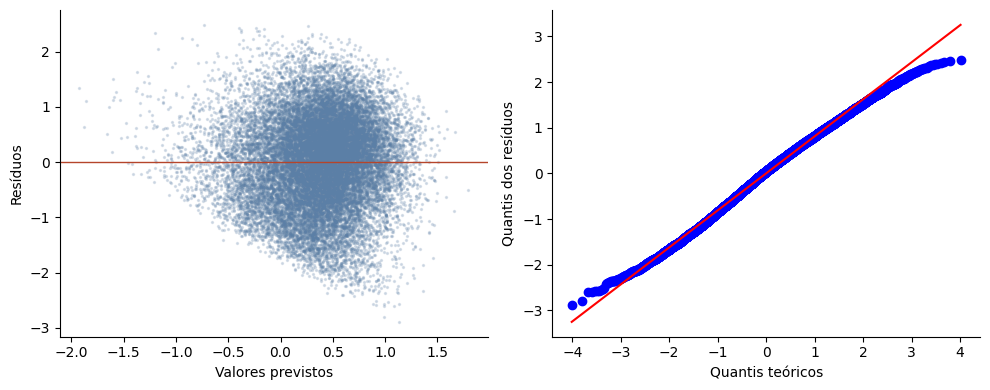

In [ ]:
X = pd.DataFrame(m.model.exog, columns=m.model.exog_names)   # inclui o intercepto, como exige o cálculo
idx = [i for i, c in enumerate(X.columns) if c != 'Intercept']
vif = pd.DataFrame({'Variável': [ROTULOS.get(X.columns[i], X.columns[i]) for i in idx],
                    'VIF': [round(variance_inflation_factor(X.values, i), 2) for i in idx]})
vif = vif.sort_values('VIF', ascending=False)
TABELAS['VIF'] = vif
print(vif.head(10).to_string(index=False))
print(f'\nMaior VIF: {vif.VIF.max():.2f}')

res = m.resid
from scipy import stats
print(f'Resíduos: assimetria = {stats.skew(res):.3f} | curtose (excesso) = {stats.kurtosis(res):.3f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(m.fittedvalues, res, s=2, alpha=0.2, color='#5b7fa6')
ax[0].axhline(0, color='#b5452b', linewidth=1)
ax[0].set_xlabel('Valores previstos'); ax[0].set_ylabel('Resíduos')
stats.probplot(res, dist='norm', plot=ax[1])
ax[1].set_title(''); ax[1].set_xlabel('Quantis teóricos'); ax[1].set_ylabel('Quantis dos resíduos')
for a in ax: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(PASTA + 'figura_residuos.png', dpi=300)
plt.show()

## 8. Observações influentes

A distância de Cook mede quanto os coeficientes mudariam se cada estudante fosse retirado. Usa-se o critério usual de 4/N para identificar observações influentes. O modelo é reestimado sem elas, e os coeficientes são comparados com os do modelo principal.

In [ ]:
m_ols = smf.ols(FORMULA, base).fit()
infl = m_ols.get_influence()
cook = infl.cooks_distance[0]
limite = 4 / len(base)
influentes = cook > limite
print(f'Distância de Cook: máxima = {cook.max():.5f} | limite 4/N = {limite:.5f}')
print(f'Observações acima do limite: {influentes.sum()} ({100 * influentes.mean():.1f}% da base)')

sem_infl = base[~influentes]
m_sem = ajustar(FORMULA, sem_infl)
comp = pd.DataFrame({'Variável': list(ATRIBUTOS.values()),
                     'Principal': [f"{m.params[t]:.3f} {sig(m.pvalues[t])}".replace('.', ',') for t in ATRIBUTOS],
                     'Sem observações influentes': [f"{m_sem.params[t]:.3f} {sig(m_sem.pvalues[t])}".replace('.', ',') for t in ATRIBUTOS]})
comp.loc[len(comp)] = ['N', int(m.nobs), int(m_sem.nobs)]
comp.loc[len(comp)] = ['R²', f'{m.rsquared:.4f}', f'{m_sem.rsquared:.4f}']
TABELAS['Observações influentes'] = comp
print(comp.to_string(index=False))

mudou = [ATRIBUTOS[t] for t in ATRIBUTOS if (m.pvalues[t] < 0.05) != (m_sem.pvalues[t] < 0.05)
         or np.sign(m.params[t]) != np.sign(m_sem.params[t])]
print('\nAtributos que mudam de sinal ou de significância:', mudou if mudou else 'nenhum')

Distância de Cook: máxima = 0.00214 | limite 4/N = 0.00017
Observações acima do limite: 1112 (4.8% da base)
                                                                                        Variável  Principal Sem observações influentes
                                                                Sexo: feminino (ref.: masculino)  0,129 ***                  0,132 ***
                                                                  Raça/cor: parda (ref.: branca) -0,161 ***                 -0,173 ***
                                                                                 Raça/cor: preta -0,229 ***                 -0,241 ***
                                                                               Raça/cor: amarela -0,245 ***                 -0,224 ***
                                                                              Raça/cor: indígena -0,496 ***                 -0,459 ***
                                          Pretensão: estudar e trabalhar (ref.: so

## 9. Incerteza da medida de proficiência

A proficiência de cada estudante é estimada pelo INEP por meio da Teoria de Resposta ao Item, e os microdados informam o erro-padrão dessa estimativa. Esta seção descreve a magnitude dessa incerteza e sua variação entre grupos. A confiabilidade marginal é calculada como 1 − (média dos erros-padrão ao quadrado ÷ variância da proficiência).

No modelo clássico de erro aditivo na variável resposta, não correlacionado com os preditores, o erro de medida aumenta a variância residual sem enviesar os coeficientes. Como o erro-padrão da TRI varia ao longo da escala, a comparação entre grupos deve reconhecer essa incerteza, sem pressupor a direção de um eventual viés.

In [ ]:
ep = base['erro_padrao_saeb']
conf = 1 - (base['erro_padrao'] ** 2).mean() / base['proficiencia'].var()
print(f'Erro-padrão da proficiência (pontos SAEB): média = {ep.mean():.1f} | mediana = {ep.median():.1f} | '
      f'mínimo = {ep.min():.1f} | máximo = {ep.max():.1f}')
print(f'Confiabilidade marginal: {conf:.3f}')

faixas = pd.qcut(base['proficiencia_saeb'], 5, labels=['1º quintil', '2º', '3º', '4º', '5º quintil'])
t_faixa = base.groupby(faixas, observed=True).agg(Proficiência_média=('proficiencia_saeb', 'mean'),
                                                  Erro_padrão_médio=('erro_padrao_saeb', 'mean')).round(1)
t_raca = base.groupby('raca_cor').agg(N=('erro_padrao_saeb', 'size'),
                                      Erro_padrão_médio=('erro_padrao_saeb', 'mean')).round(1)
t_sexo = base.groupby('sexo').agg(N=('erro_padrao_saeb', 'size'),
                                  Erro_padrão_médio=('erro_padrao_saeb', 'mean')).round(1)
print('\nPor faixa de proficiência:'); print(t_faixa.to_string())
print('\nPor raça/cor:'); print(t_raca.to_string())
print('\nPor sexo:'); print(t_sexo.to_string())
TABELAS['Incerteza por faixa'] = t_faixa.reset_index().rename(columns={'proficiencia_saeb': 'Faixa'})
TABELAS['Incerteza por grupo'] = pd.concat([t_raca.reset_index().rename(columns={'raca_cor': 'Grupo'}),
                                            t_sexo.reset_index().rename(columns={'sexo': 'Grupo'})])

Erro-padrão da proficiência (pontos SAEB): média = 22.9 | mediana = 21.4 | mínimo = 16.4 | máximo = 39.3
Confiabilidade marginal: 0.785

Por faixa de proficiência:
                   Proficiência_média  Erro_padrão_médio
proficiencia_saeb                                       
1º quintil                      196.5               30.2
2º                              241.0               23.5
3º                              272.1               20.2
4º                              299.9               19.4
5º quintil                      338.2               21.4

Por raça/cor:
              N  Erro_padrão_médio
raca_cor                          
Amarela     512               23.4
Branca     7039               22.4
Indígena    249               25.3
Parda     11962               23.0
Preta      3234               23.6

Por sexo:
               N  Erro_padrão_médio
sexo                               
Feminino   12669               22.4
Masculino  10327               23.6


## 10. Múltiplos testes

Quando muitos testes são feitos, alguns resultados podem ser significativos por acaso. Os testes da pesquisa são organizados em famílias:

- **Família confirmatória:** os 25 coeficientes dos atributos no modelo principal, que respondem ao objetivo da pesquisa. Nela aplicam-se as correções de Holm (controle do erro por família) e de Benjamini-Hochberg (controle da taxa de falsas descobertas).
- **Análises de robustez e exploratórias:** sensibilidade, categorias das ordinais, modelos em etapas e comparações descritivas. Servem para verificar a estabilidade dos resultados e são interpretadas pela direção e pela magnitude, não por decisões isoladas de significância.

In [ ]:
from statsmodels.stats.multitest import multipletests
p = np.array([m.pvalues[t] for t in ATRIBUTOS])
holm = multipletests(p, method='holm')[1]
bh = multipletests(p, method='fdr_bh')[1]
mult = pd.DataFrame({'Variável': list(ATRIBUTOS.values()),
                     'p original': [fmt_p(x) for x in p],
                     'p ajustado (Holm)': [fmt_p(x) for x in holm],
                     'p ajustado (Benjamini-Hochberg)': [fmt_p(x) for x in bh],
                     'Sig. original': [sig(x) for x in p],
                     'Sig. após Holm': [sig(x) for x in holm]})
TABELAS['Múltiplos testes'] = mult
print(mult.to_string(index=False))
muda = mult[(mult['Sig. original'] != 'ns') & (mult['Sig. após Holm'] == 'ns')]['Variável'].tolist()
print('\nAtributos que deixam de ser significativos após a correção de Holm:', muda if muda else 'nenhum')

                                                                                        Variável p original p ajustado (Holm) p ajustado (Benjamini-Hochberg) Sig. original Sig. após Holm
                                                                Sexo: feminino (ref.: masculino)    < 0,001           < 0,001                         < 0,001           ***            ***
                                                                  Raça/cor: parda (ref.: branca)    < 0,001           < 0,001                         < 0,001           ***            ***
                                                                                 Raça/cor: preta    < 0,001           < 0,001                         < 0,001           ***            ***
                                                                               Raça/cor: amarela    < 0,001           < 0,001                         < 0,001           ***            ***
                                                                 

## Exportação

In [ ]:
with pd.ExcelWriter(PASTA + 'tabelas_regressao.xlsx') as xw:
    for nome, t in TABELAS.items():
        t.to_excel(xw, sheet_name=nome[:31], index=False)
print('Tabelas salvas em', PASTA + 'tabelas_regressao.xlsx')

Tabelas salvas em /content/drive/MyDrive/dissertacao/tabelas_regressao.xlsx
